# Bean Leaf Disease Classification — End-to-End ML Pipeline

**Problem.** Beans are a staple food and income crop for millions of smallholder farmers in East Africa.
*Angular leaf spot* and *bean rust* can destroy a large share of a harvest, and farmers often lack quick access to
agronomists. This notebook builds an image classifier that tells, from a single phone photo of a leaf, whether it is
**healthy**, has **angular leaf spot**, or has **bean rust**.

**Data.** The [iBeans dataset](https://github.com/AI-Lab-Makerere/ibean) (Makerere AI Lab, Uganda): field photos
taken with smartphones and labelled by experts at the National Crops Resources Research Institute (NaCRRI).

**Notebook outline**
1. Data acquisition
2. Exploratory analysis & feature interpretation (the "story" of the data)
3. Preprocessing pipeline
4. Model creation (vanilla baseline vs. optimised custom CNN, both trained from scratch)
5. Training with optimisation techniques
6. Evaluation (accuracy, loss, precision, recall, F1, ROC-AUC, confusion matrix)
7. Saving the model
8. Prediction functions
9. How retraining works

In [1]:
import os, sys, json, time
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image

from src import config as C
from src import preprocessing as pp
from src import model as M

COLORS = C.CLASS_COLORS                     # fixed colour per class, colour-blind safe as a set
LABELS = C.CLASS_LABELS
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
print("TensorFlow", tf.__version__)

TensorFlow 2.18.1


## 1. Data acquisition
The dataset is downloaded from the Hugging Face mirror of iBeans if it is not on disk yet. The original `validation` split is merged into `train`; a stratified validation split is re-created later.

In [2]:
if sum(pp.count_images(C.TRAIN_DIR).values()) == 0:
    pp.download_dataset()

counts = pd.DataFrame({"train": pp.count_images(C.TRAIN_DIR), "test": pp.count_images(C.TEST_DIR)})
counts.index = [LABELS[c] for c in counts.index]
counts.loc["Total"] = counts.sum()
counts

,train,test
Angular Leaf Spot,389,43
Bean Rust,393,43
Healthy,385,42
Total,1167,128


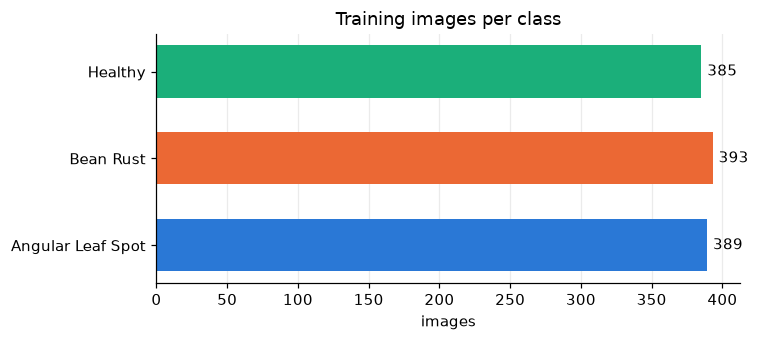

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
tr = pp.count_images(C.TRAIN_DIR)
bars = ax.barh([LABELS[c] for c in C.CLASS_NAMES], [tr[c] for c in C.CLASS_NAMES],
               color=[COLORS[c] for c in C.CLASS_NAMES], height=0.6)
ax.bar_label(bars, padding=4)
ax.set_title("Training images per class"); ax.set_xlabel("images"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

The classes are **balanced** (~390 training images each), so plain accuracy is a meaningful metric and no resampling is needed for the initial training.

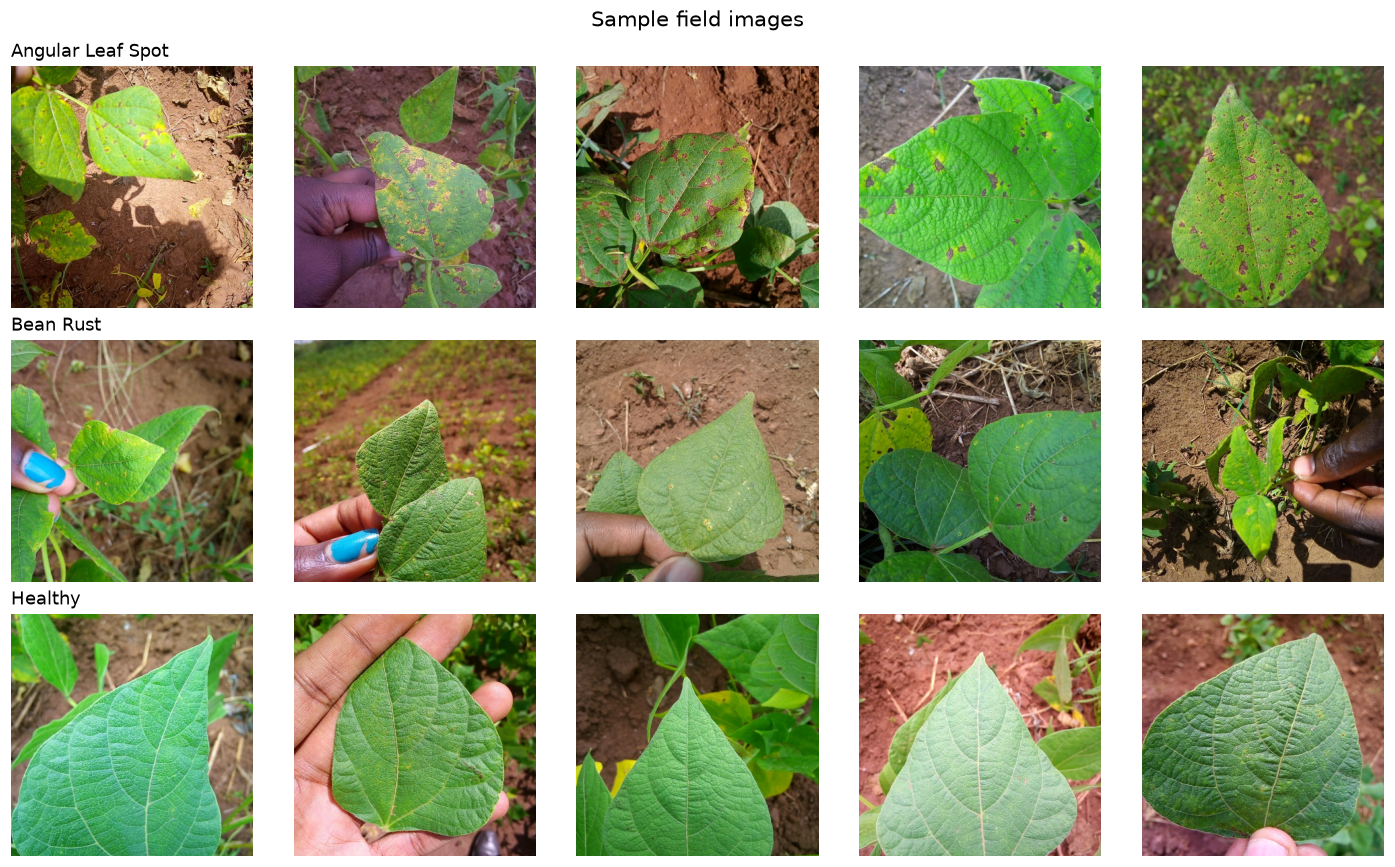

Original image sizes (sampled): {(500, 500): 47}


In [4]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for r, cls in enumerate(C.CLASS_NAMES):
    files = sorted((C.TRAIN_DIR / cls).glob("*.jpg"))[:5]
    for c, f in enumerate(files):
        axes[r, c].imshow(Image.open(f)); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(LABELS[cls], loc="left", fontsize=12)
plt.suptitle("Sample field images", fontsize=14); plt.tight_layout(); plt.show()

sizes = pd.Series([Image.open(p).size for p, _ in pp.list_images(C.TRAIN_DIR)[::25]]).value_counts()
print("Original image sizes (sampled):", sizes.to_dict())

## 2. Exploratory analysis — interpreting features of the images

Raw pixels are hard to reason about, so we extract interpretable features from every image
(`src/preprocessing.py::image_features`):

| Feature | Meaning |
|---|---|
| `green_ratio` | share of pixels where green clearly dominates — healthy leaf tissue |
| `lesion_ratio` | share of saturated brown / yellow / rust-coloured pixels (HSV hue 5–35°) — disease lesions |
| `edge_density` | share of strong-gradient pixels — texture (spots, pustules, veins, background) |
| `brightness`, `saturation` | lighting conditions of the photo |
| `mean_r/g/b` | average colour channels |

In [5]:
feat = pd.read_csv(C.FEATURES_CSV) if C.FEATURES_CSV.exists() else pp.build_feature_table()
feat["Class"] = feat["class"].map(LABELS)
feat.groupby("Class")[["green_ratio", "lesion_ratio", "edge_density", "brightness", "saturation"]].agg(["mean", "std"]).round(3)

green_ratio        lesion_ratio        edge_density         \
                         mean    std         mean    std         mean    std   
Class                                                                          
Angular Leaf Spot       0.455  0.179        0.174  0.165        0.151  0.077   
Bean Rust               0.434  0.164        0.199  0.160        0.163  0.083   
Healthy                 0.687  0.157        0.098  0.095        0.160  0.072   

                  brightness        saturation         
                        mean    std       mean    std  
Class                                                  
Angular Leaf Spot      0.585  0.087      0.526  0.121  
Bean Rust              0.543  0.094      0.475  0.147  
Healthy                0.606  0.078      0.488  0.125

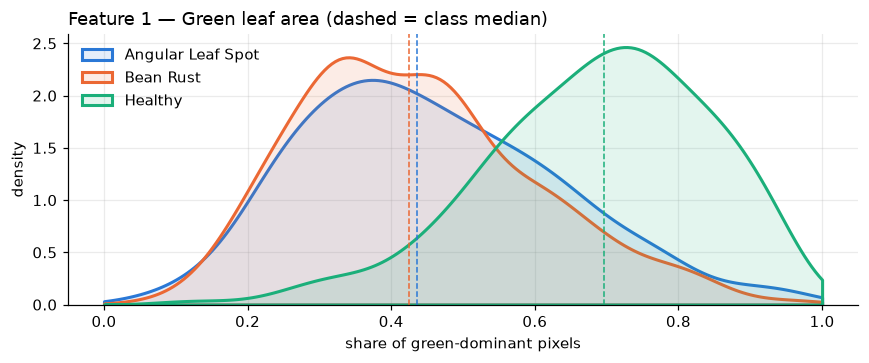

In [6]:
def feature_plot(col, title, xlabel):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for cls in C.CLASS_NAMES:
        sns.kdeplot(feat.loc[feat["class"] == cls, col], ax=ax, color=COLORS[cls], lw=2,
                    label=LABELS[cls], fill=True, alpha=0.12, clip=(0, 1))
        ax.axvline(feat.loc[feat["class"] == cls, col].median(), color=COLORS[cls], lw=1, ls="--")
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.set_ylabel("density"); ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

feature_plot("green_ratio", "Feature 1 — Green leaf area (dashed = class median)", "share of green-dominant pixels")

**Feature 1 — green leaf area.** Healthy leaves have a median of ~70 % green-dominant pixels, whereas both diseased
classes sit around 43 %. Disease visibly *removes green tissue*: lesions replace chlorophyll-rich areas. This single
feature already separates healthy from diseased leaves well, but the two disease curves overlap almost completely —
green area alone cannot tell *which* disease a leaf has.

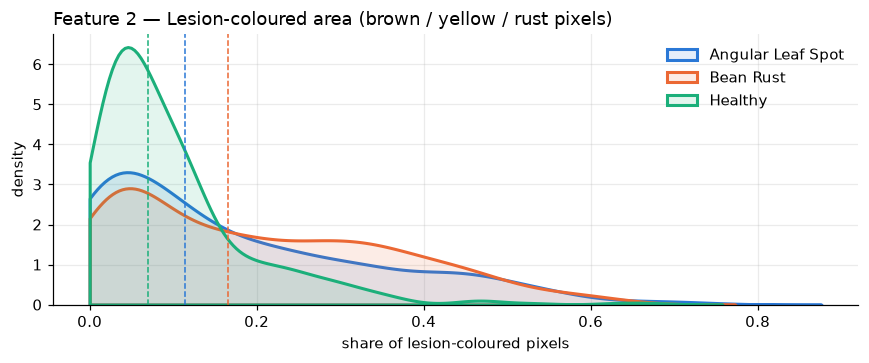

In [7]:
feature_plot("lesion_ratio", "Feature 2 — Lesion-coloured area (brown / yellow / rust pixels)", "share of lesion-coloured pixels")

**Feature 2 — lesion-coloured area.** Bean rust has the most rust/brown-coloured pixels (median ≈ 17 %), followed by
angular leaf spot (≈ 12 %) and healthy leaves (≈ 7 %; soil and dry spots in the background are never zero). Rust
pustules are reddish-brown and spread over the whole leaf, while angular leaf spot lesions are greyish-brown and
bounded by veins, so they contribute fewer "rust-hue" pixels. The ordering matches plant-pathology descriptions,
but the distributions overlap — colour is a hint, not a decision rule.

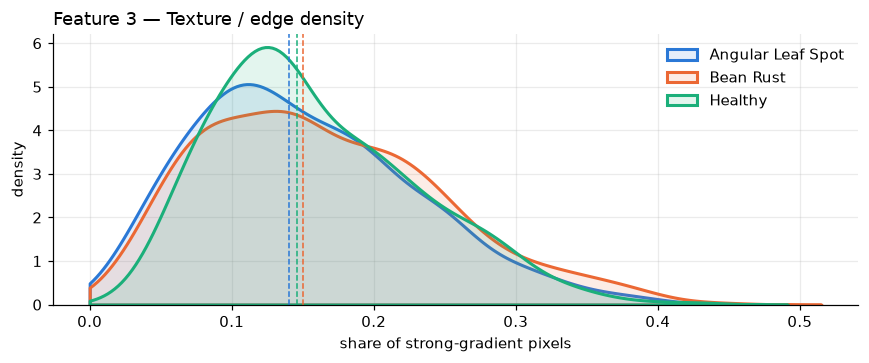

In [8]:
feature_plot("edge_density", "Feature 3 — Texture / edge density", "share of strong-gradient pixels")

**Feature 3 — texture (edge density).** Surprisingly, edge density is almost identical across the three classes
(≈ 0.14–0.15). Field photos contain soil, other leaves and veins, so global texture is dominated by the background
rather than by the disease. **Global hand-crafted statistics therefore cannot distinguish the two diseases** —
the model must learn *local spatial patterns* (shape of the spots: angular, vein-limited patches vs. small round
pustules). This motivates a convolutional neural network rather than a classic model on summary features.

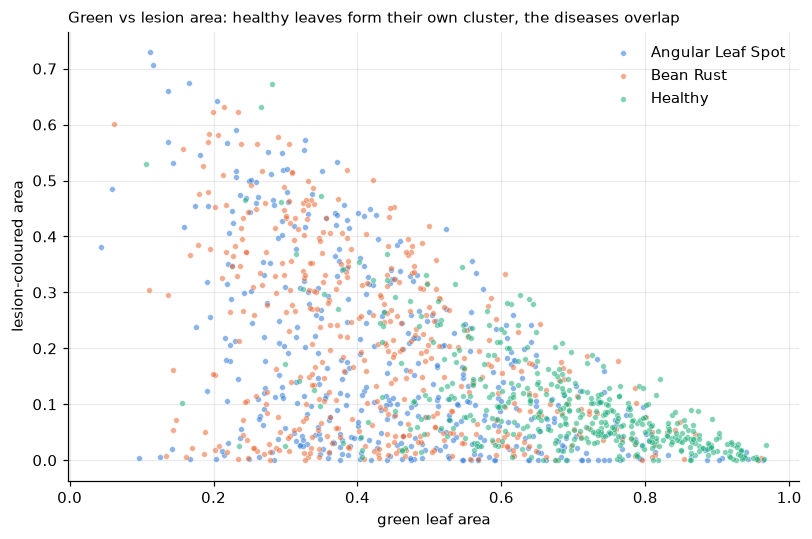

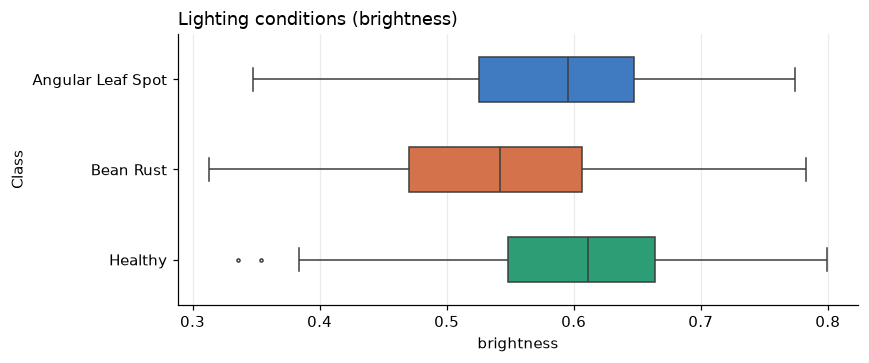

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for cls in C.CLASS_NAMES:
    d = feat[feat["class"] == cls]
    ax.scatter(d["green_ratio"], d["lesion_ratio"], s=14, alpha=0.55, color=COLORS[cls], label=LABELS[cls],
               edgecolors="white", linewidths=0.4)
ax.set_xlabel("green leaf area"); ax.set_ylabel("lesion-coloured area")
ax.set_title("Green vs lesion area: healthy leaves form their own cluster, the diseases overlap", loc="left", fontsize=10)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.4))
sns.boxplot(data=feat, x="brightness", y="Class", hue="Class", palette={LABELS[k]: v for k, v in COLORS.items()},
            ax=ax, width=0.5, fliersize=2, legend=False)
ax.set_title("Lighting conditions (brightness)", loc="left"); plt.tight_layout(); plt.show()

**The story.** Disease shows up as *lost green tissue* and *more brown/rust pixels*, which makes "healthy vs.
diseased" visually easy. Telling the two diseases apart requires recognising the **shape and distribution of the
lesions**, and photos vary in lighting (bean-rust photos are slightly darker on average) and background. We
therefore (a) use a convolutional network, which learns spatial patterns such as lesion shape directly from pixels, and (b) augment the data with flips, rotations,
zoom and contrast changes so the model becomes robust to camera angle and lighting rather than learning shortcuts.

## 3. Preprocessing pipeline
Every image — training data, uploaded retraining data and prediction requests — goes through the **same**
function `pp.load_image`:
1. decode (JPEG/PNG/…), apply EXIF orientation (phone photos), convert to 3-channel RGB;
2. resize 500×500 → **160×160** (bilinear) — keeps lesion detail while making CPU training/serving feasible;
3. keep values in [0, 255]; **scaling to [0, 1] happens inside the model** (`Rescaling` layer), so the deployed
   API cannot forget a preprocessing step.

Then: stratified 85/15 train/validation split, uint8 storage (4× less memory), `tf.data` batching + prefetching,
and on-the-fly **data augmentation** layers that are only active during training.

In [10]:
items = pp.list_images(C.TRAIN_DIR)
train_items, val_items = pp.stratified_split(items, val_fraction=C.VAL_SPLIT)
X_train, y_train = pp.load_arrays(train_items)
X_val, y_val = pp.load_arrays(val_items)
X_test, y_test = pp.load_arrays(pp.list_images(C.TEST_DIR))
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape, "dtype", X_train.dtype)
print("train class counts", np.bincount(y_train), "| val", np.bincount(y_val), "| test", np.bincount(y_test))
print("pixel range", X_train.min(), "-", X_train.max())

ds_train = pp.make_dataset(X_train, y_train, shuffle=True)
ds_val = pp.make_dataset(X_val, y_val)
ds_test = pp.make_dataset(X_test, y_test)
ds_train.element_spec

train (994, 160, 160, 3) val (173, 160, 160, 3) test (128, 160, 160, 3) dtype uint8
train class counts [331 335 328] | val [58 58 57] | test [43 43 42]
pixel range 0 - 255


(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name=None),
 TensorSpec(shape=(None, 3), dtype=tf.float32, name=None))

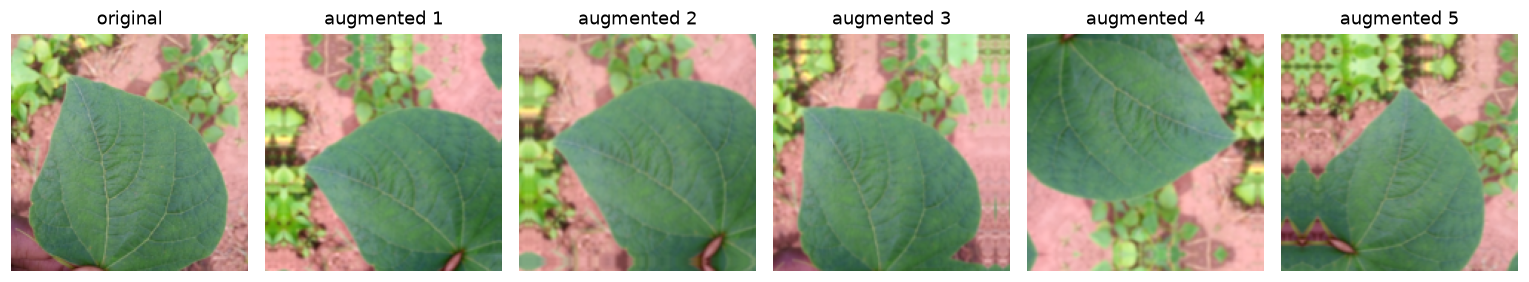

In [11]:
aug = M.build_model().get_layer("augmentation")
img = X_train[3:4].astype("float32")
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(img[0].astype("uint8")); axes[0].set_title("original"); axes[0].axis("off")
for i in range(1, 6):
    axes[i].imshow(np.clip(aug(img, training=True)[0].numpy(), 0, 255).astype("uint8"))
    axes[i].set_title(f"augmented {i}"); axes[i].axis("off")
plt.tight_layout(); plt.show()

## 4. Model creation

### 4.1 Baseline: small CNN trained from scratch (vanilla, no optimisation)
A reference point to show what the optimisation techniques buy us.

In [12]:
def build_baseline():
    L = tf.keras.layers
    return tf.keras.Sequential([
        tf.keras.Input((C.IMG_SIZE, C.IMG_SIZE, 3)),
        L.Rescaling(1 / 255.),
        L.Conv2D(16, 3, activation="relu"), L.MaxPooling2D(),
        L.Conv2D(32, 3, activation="relu"), L.MaxPooling2D(),
        L.Conv2D(64, 3, activation="relu"), L.MaxPooling2D(),
        L.Flatten(), L.Dense(64, activation="relu"), L.Dense(3, activation="softmax"),
    ], name="baseline_cnn")

tf.keras.utils.set_random_seed(C.SEED)
baseline = build_baseline()
baseline.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist_base = baseline.fit(ds_train, validation_data=ds_val, epochs=10, verbose=2)
print(f"baseline training time: {time.time() - t0:.0f}s")
baseline_metrics = M.evaluate(baseline, X_test, y_test)
print({k: round(baseline_metrics[k], 3) for k in ["accuracy", "loss", "precision", "recall", "f1"]})

Epoch 1/10


D:\bean-disease\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


32/32 - 6s - 191ms/step - accuracy: 0.3390 - loss: 1.0959 - val_accuracy: 0.3584 - val_loss: 1.0939


Epoch 2/10


32/32 - 5s - 172ms/step - accuracy: 0.4346 - loss: 1.0827 - val_accuracy: 0.4277 - val_loss: 1.0794


Epoch 3/10


... (13 outputs left out)

Epoch 10/10


32/32 - 6s - 183ms/step - accuracy: 0.6751 - loss: 0.7579 - val_accuracy: 0.3757 - val_loss: 1.6693


baseline training time: 67s


{'accuracy': 0.383, 'loss': 1.673, 'precision': 0.451, 'recall': 0.381, 'f1': 0.257}


### 4.2 Optimised model: custom CNN trained from scratch
No pretrained weights are used: every weight starts from a random initialisation and is learned from the iBeans
images only. Optimisation techniques:
* **Architecture** — a strided 3×3 *stem* convolution followed by three blocks of **depthwise-separable
  convolutions** (64 → 128 → 256 filters). Separable convolutions need far fewer multiplications and parameters
  than standard ones, so the network trains on a laptop CPU and serves quickly on a small cloud instance.
* **Batch Normalisation** after every convolution — stabilises and speeds up training from scratch.
* **Global Average Pooling** instead of Flatten + large Dense layers — far fewer parameters, less over-fitting.
* **Regularisation** — L2 (1e-4) on every convolution and the output layer; Dropout 0.1 after each block and 0.4
  before the classifier.
* **Data augmentation** — random flip, rotation (±15 %), zoom (±15 %), translation (±10 %) and contrast (±15 %),
  active only during training.
* **Optimiser** — Adam (initial learning rate 1e-3).
* **Early stopping** (patience 12, restore best weights) and **ReduceLROnPlateau** (halve the learning rate after
  4 epochs without improvement) on validation loss.


In [13]:
tf.keras.utils.set_random_seed(C.SEED)
model = M.build_model()
M.compile_model(model, lr=1e-3)
model.summary()

Model: "bean_disease_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaling (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 80, 80, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 80, 80, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (ReLU)                │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_sepconv1                 │ (None, 80, 80, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 80, 80, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (ReLU)             │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_sepconv2                 │ (None, 80, 80, 64)     │         4,672 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 80, 80, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (ReLU)             │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_sepconv1                 │ (None, 40, 40, 128)    │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 40, 40, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (ReLU)             │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_sepconv2                 │ (None, 40, 40, 128)    │        17,536 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 40, 40, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (ReLU)             │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_sepconv1                 │ (None, 20, 20, 256)    │        33,92

 Total params: 140,419 (548.51 KB)

 Trainable params: 138,563 (541.26 KB)

 Non-trainable params: 1,856 (7.25 KB)

## 5. Training from scratch


In [14]:
t0 = time.time()
hist = model.fit(ds_train, validation_data=ds_val, epochs=C.TRAIN_EPOCHS, callbacks=M.callbacks(), verbose=2)
best = int(np.argmin(hist.history["val_loss"]))
print(f"{len(hist.history['loss'])} epochs in {time.time() - t0:.0f}s; best epoch {best + 1} "
      f"(val_loss {hist.history['val_loss'][best]:.3f}, val_accuracy {hist.history['val_accuracy'][best]:.3f})")


Epoch 1/80


D:\bean-disease\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


32/32 - 57s - 2s/step - accuracy: 0.5684 - loss: 1.0433 - precision: 0.5930 - recall: 0.5101 - val_accuracy: 0.3353 - val_loss: 1.1739 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010


Epoch 2/80


32/32 - 71s - 2s/step - accuracy: 0.6781 - loss: 0.8374 - precision: 0.7117 - recall: 0.6308 - val_accuracy: 0.3353 - val_loss: 1.1739 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010


Epoch 3/80


... (20 outputs left out)

32/32 - 137s - 4s/step - accuracy: 0.8008 - loss: 0.5491 - precision: 0.8158 - recall: 0.7797 - val_accuracy: 0.3353 - val_loss: 1.8052 - val_precision: 0.3353 - val_recall: 0.3353 - learning_rate: 2.5000e-04


Epoch 14/80


32/32 - 66s - 2s/step - accuracy: 0.8249 - loss: 0.4939 - precision: 0.8391 - recall: 0.8028 - val_accuracy: 0.3468 - val_loss: 1.8304 - val_precision: 0.3571 - val_recall: 0.3468 - learning_rate: 1.2500e-04


14 epochs in 1312s; best epoch 2 (val_loss 1.174, val_accuracy 0.335)


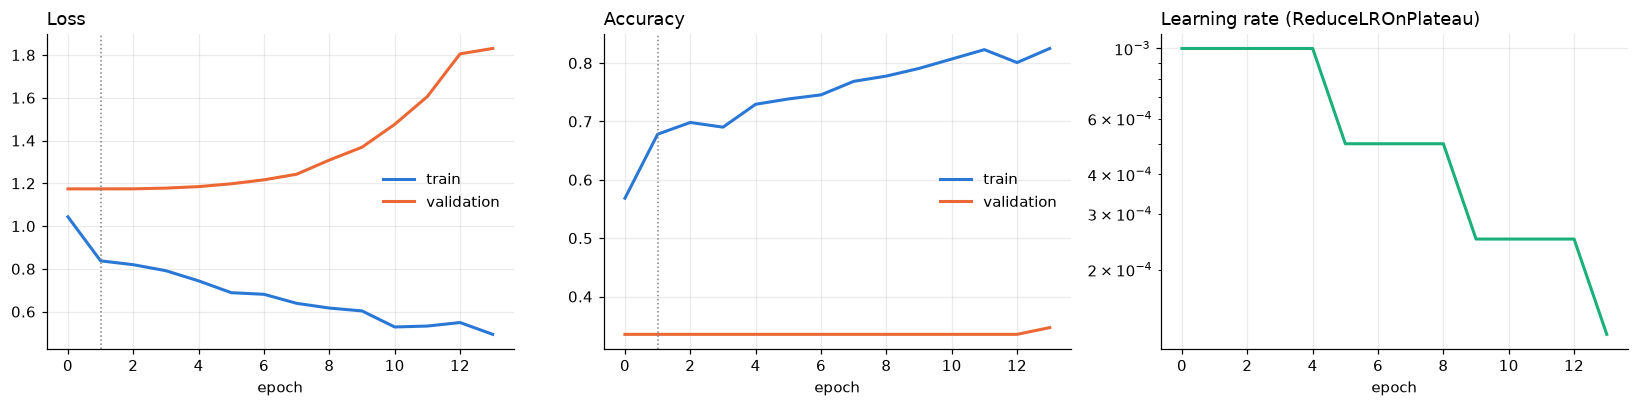

In [15]:
h = hist.history
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(h[metric], color="#2a78d6", lw=2, label="train")
    ax.plot(h["val_" + metric], color="#eb6834", lw=2, label="validation")
    ax.axvline(best, color="grey", ls=":", lw=1)
    ax.set_title(metric.capitalize(), loc="left"); ax.set_xlabel("epoch"); ax.legend(frameon=False)
lr = h.get("learning_rate", h.get("lr", []))
axes[2].plot(lr, color="#1baf7a", lw=2); axes[2].set_yscale("log")
axes[2].set_title("Learning rate (ReduceLROnPlateau)", loc="left"); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()


_Training-curve interpretation is filled in after the run._


## 6. Evaluation on the held-out test set (never seen during training or model selection)

In [16]:
metrics = M.evaluate(model, X_test, y_test)
summary = pd.DataFrame({
    "Baseline CNN (vanilla)": {k: baseline_metrics[k] for k in ["accuracy", "loss", "precision", "recall", "f1", "roc_auc"]},
    "Custom CNN (optimised, from scratch)": {k: metrics[k] for k in ["accuracy", "loss", "precision", "recall", "f1", "roc_auc"]},
}).round(4)
summary.index = ["Accuracy", "Loss (cross-entropy)", "Precision (macro)", "Recall (macro)", "F1-score (macro)", "ROC-AUC (macro, OvR)"]
summary

,Baseline CNN (vanilla),"Custom CNN (optimised, from scratch)"
Accuracy,0.3828,0.3359
Loss (cross-entropy),1.6733,1.0990
Precision (macro),0.4508,0.1120
Recall (macro),0.3810,0.3333
F1-score (macro),0.2571,0.1676
"ROC-AUC (macro, OvR)",0.8158,0.5851


In [17]:
report = pd.DataFrame(metrics["per_class"]).T.round(3)
report.index = [LABELS.get(i, i) for i in report.index]
report

,precision,recall,f1-score,support
Angular Leaf Spot,0.336,1.000,0.503,43.000
Bean Rust,0.000,0.000,0.000,43.000
Healthy,0.000,0.000,0.000,42.000
accuracy,0.336,0.336,0.336,0.336
macro avg,0.112,0.333,0.168,128.000
weighted avg,0.113,0.336,0.169,128.000


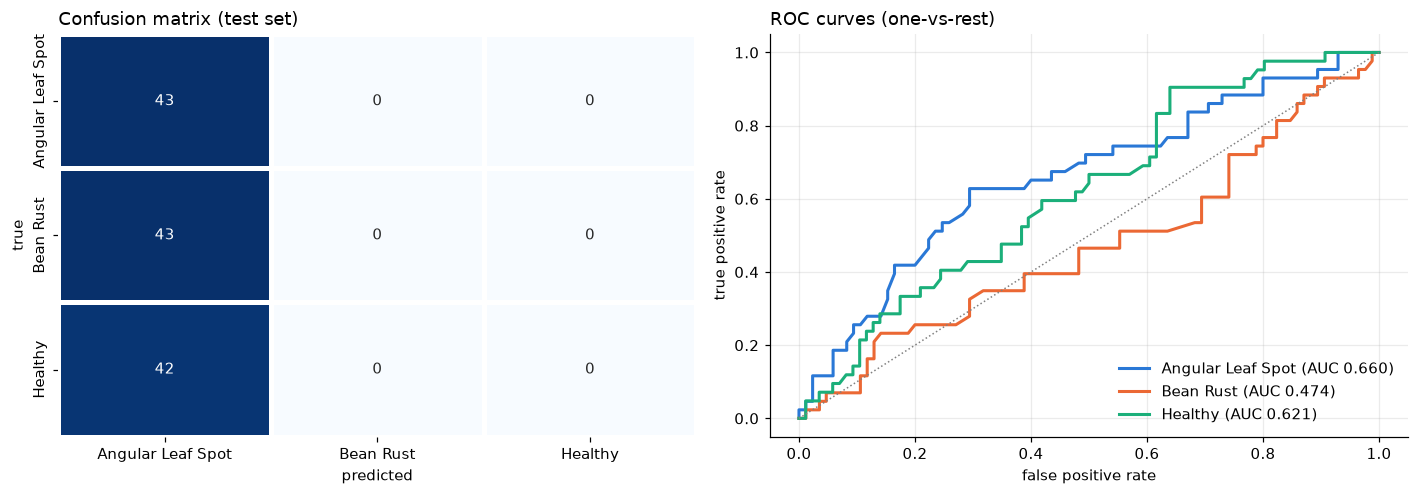

In [18]:
from sklearn.metrics import roc_curve, auc
cm = np.array(metrics["confusion_matrix"])
probs = model.predict(ds_test, verbose=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], linewidths=2, linecolor="white",
            xticklabels=[LABELS[c] for c in C.CLASS_NAMES], yticklabels=[LABELS[c] for c in C.CLASS_NAMES])
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("Confusion matrix (test set)", loc="left")
for i, cls in enumerate(C.CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test == i, probs[:, i])
    axes[1].plot(fpr, tpr, color=COLORS[cls], lw=2, label=f"{LABELS[cls]} (AUC {auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curves (one-vs-rest)", loc="left")
axes[1].legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

_Test-set interpretation is filled in after the run._


## 7. Save the model
The model is saved in **HDF5 (`.h5`)** format together with its metrics/version file, which the API reads to report the production model version.

In [19]:
version = M.save_model(model, metrics, {"trigger": "initial_training (notebook)", "n_train_images": len(items),
                                         "baseline_test_accuracy": baseline_metrics["accuracy"]})
print("saved", C.MODEL_PATH, "| version", version, "|", round(C.MODEL_PATH.stat().st_size / 1e6, 1), "MB")
reloaded = M.load_model()
assert np.allclose(reloaded.predict(ds_test, verbose=0), probs, atol=1e-5)
print("reloaded model gives identical predictions")

saved D:\bean-disease\models\bean_disease_cnn.h5 | version v20261123-203902 | 0.7 MB


reloaded model gives identical predictions


## 8. Prediction functions
`src/prediction.py` wraps the saved model; the same code serves the API.

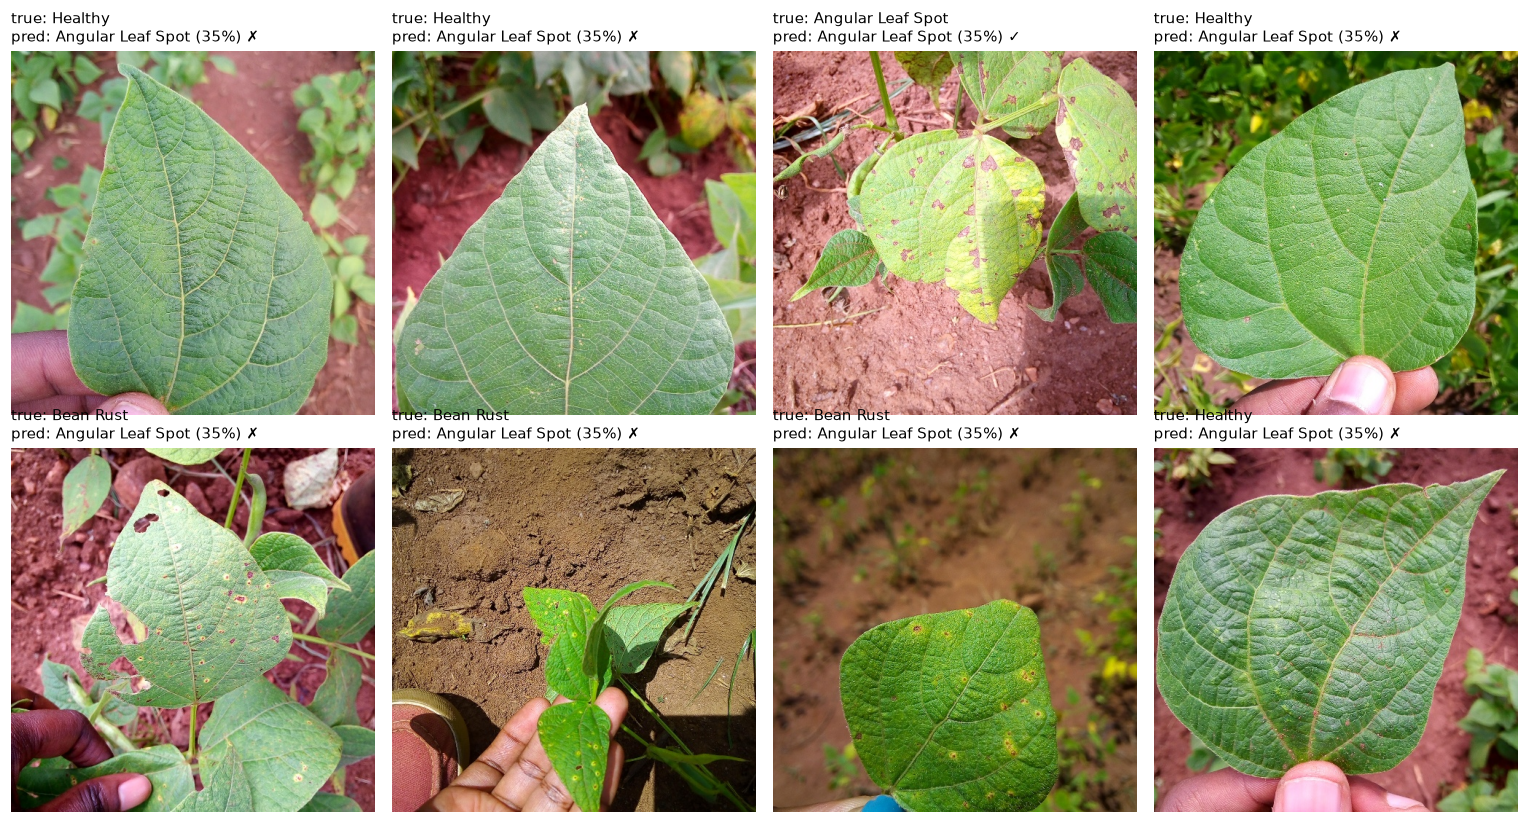

{
  "predicted_class": "angular_leaf_spot",
  "label": "Angular Leaf Spot",
  "confidence": 0.3486846089363098,
  "probabilities": {
    "angular_leaf_spot": 0.3486846089363098,
    "bean_rust": 0.3247291147708893,
    "healthy": 0.3265862762928009
  },
  "advice": "Angular leaf spot (Phaeoisariopsis griseola). Remove infected leaves, avoid overhead watering, rotate crops and use certified disease-free seed.",
  "model_version": "v20261123-203902",
  "latency_ms": 105.7
}


In [20]:
from src.prediction import Predictor
predictor = Predictor().load()

test_items = pp.list_images(C.TEST_DIR)
rng = np.random.default_rng(7)
sample = [test_items[i] for i in rng.choice(len(test_items), 8, replace=False)]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, (path, label) in zip(axes.ravel(), sample):
    res = predictor.predict(path)
    ok = res["predicted_class"] == C.CLASS_NAMES[label]
    ax.imshow(Image.open(path)); ax.axis("off")
    ax.set_title(f"true: {LABELS[C.CLASS_NAMES[label]]}\npred: {res['label']} ({res['confidence']:.0%}) {'✓' if ok else '✗'}",
                 fontsize=10, loc="left")
plt.tight_layout(); plt.show()
print(json.dumps(predictor.predict(sample[0][0]), indent=2))

## 9. Retraining
Retraining is implemented in `src/model.py::retrain` and exposed by the API (`POST /retrain`) and the UI button:

1. **Upload + save to database** — bulk images (or a zip of class folders) are validated, stored under
   `data/uploads/<class>/` and recorded in the SQLite `uploads` table.
2. **Preprocessing** — uploaded images go through the same `pp.load_image` pipeline, mixed with a replay sample of
   the original training data (prevents catastrophic forgetting) and class-weighted.
3. **Retraining from the custom pretrained model** — the current production `bean_disease_cnn.h5` (the model trained
   from scratch above) is loaded as the starting point and fine-tuned (Adam lr 1e-4, BatchNorm statistics frozen,
   early stopping).
4. **Evaluation + promotion** — the new model is evaluated on the fixed test set and only replaces the production
   model if its accuracy does not drop; the previous model is archived in `models/archive/`.

**Triggers:** a manual button in the UI, or automatically when the number of new uploaded images reaches
`RETRAIN_THRESHOLD` (default 30).